# EDA: Dự đoán lưu lượng giao thông theo giờ
**Người thực hiện:** Phùng Anh Vũ  
**Mục tiêu:** Tìm hiểu dữ liệu, trực quan hóa lưu lượng theo thời gian và thời tiết, ghi nhận các phát hiện phục vụ nhóm. Các biểu đồ mô tả mối liên hệ, không chứng minh quan hệ nhân quả.

Nguồn dữ liệu: [UCI Metro Interstate Traffic Volume](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume). Dữ liệu ghi nhận lưu lượng theo giờ trên tuyến I-94 hướng tây cùng thông tin thời tiết và ngày lễ.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)
project = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "metro_interstate_traffic_volume"] if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").exists()), Path.cwd())
path = project / "data" / "Metro_Interstate_Traffic_Volume.csv"
if not path.exists():
    raise FileNotFoundError(f"Không tìm thấy dữ liệu: {path}")
df = pd.read_csv(path, keep_default_na=False)
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
print("Kích thước:", df.shape)
display(df.head())

Kích thước: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 1. Tổng quan dữ liệu
`traffic_volume` là số xe/giờ; `temp` đo bằng Kelvin; `rain_1h` và `snow_1h` là lượng mưa/tuyết trong giờ; `clouds_all` là phần trăm mây che phủ. Các trường `holiday`, `weather_main`, `weather_description` mô tả ngày lễ và thời tiết.

In [4]:
df.info()
display(df.describe(include="all").T)
print("Khoảng thời gian:", df.date_time.min(), "đến", df.date_time.max())
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số timestamp lặp:", df.date_time.duplicated().sum())
display(pd.DataFrame({"null": df.isna().sum(), "rỗng": df.astype("string").apply(lambda s: s.str.strip().eq("").sum())}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              48204 non-null  object        
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  object        
 6   weather_description  48204 non-null  object        
 7   date_time            48204 non-null  datetime64[ns]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 3.3+ MB
Khoảng thời gian: 2012-10-02 09:00:00 đến 2018-09-30 23:00:00
Số dòng trùng hoàn toàn: 17
Số timestamp lặp: 7629


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
holiday,48204,12,None,48143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temp,48204.0,NaN,NaN,NaN,281.20587,0.0,272.16,282.45,291.806,310.07,13.338232
rain_1h,48204.0,NaN,NaN,NaN,0.334264,0.0,0.0,0.0,0.0,9831.3,44.789133
snow_1h,48204.0,NaN,NaN,NaN,0.000222,0.0,0.0,0.0,0.0,0.51,0.008168
clouds_all,48204.0,NaN,NaN,NaN,49.362231,0.0,1.0,64.0,90.0,100.0,39.01575
weather_main,48204,11,Clouds,15164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_description,48204,38,sky is clear,11665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_time,48204,NaN,NaN,NaN,2016-01-05 10:46:16.773711616,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN
traffic_volume,48204.0,NaN,NaN,NaN,3259.818355,0.0,1193.0,3380.0,4933.0,7280.0,1986.86067


,null,rỗng
holiday,0,0
temp,0,0
rain_1h,0,0
snow_1h,0,0
clouds_all,0,0
weather_main,0,0
weather_description,0,0
date_time,0,0
traffic_volume,0,0


**Nhận xét:** Dữ liệu gồm 48.204 dòng, 9 cột, từ 02/10/2012 đến 30/09/2018. Có 17 dòng trùng hoàn toàn và 7.629 dòng có timestamp đã xuất hiện trước đó. Không phát hiện null hoặc chuỗi rỗng theo phép kiểm tra trên; vẫn cần kiểm tra giá trị bất thường.

Các timestamp có thể lặp do nhiều mô tả thời tiết. Để tránh một giờ được tính nhiều lần trong phân tích lưu lượng theo thời gian, các biểu đồ theo giờ bên dưới dùng trung bình lưu lượng theo timestamp; dữ liệu gốc không bị thay đổi.

In [7]:
hourly = df.dropna(subset=["date_time"]).groupby("date_time", as_index=False)["traffic_volume"].mean()
hourly["hour"] = hourly.date_time.dt.hour
hourly["weekday"] = hourly.date_time.dt.dayofweek
hourly["month"] = hourly.date_time.dt.month
print("Số timestamp duy nhất:", len(hourly))

Số timestamp duy nhất: 40575


## 2. Phân bố lưu lượng

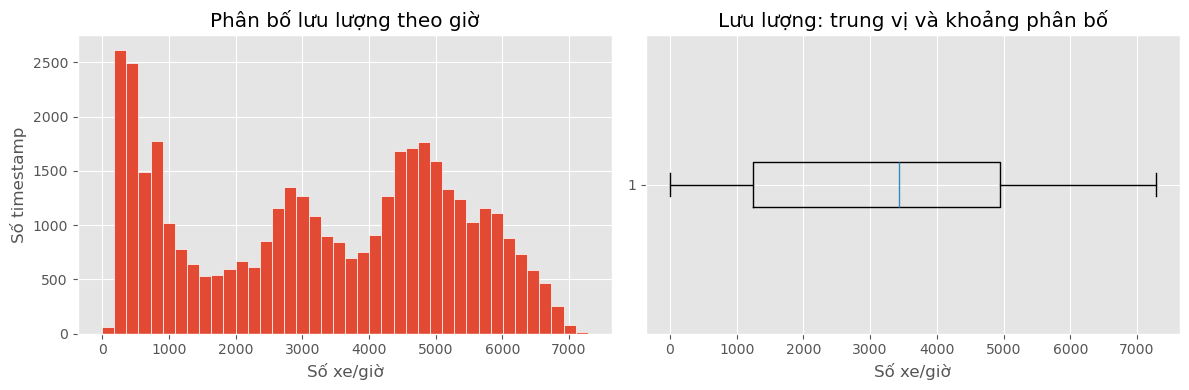

count    40575.000000
mean      3290.650474
std       1984.772909
min          0.000000
25%       1248.500000
50%       3427.000000
75%       4952.000000
max       7280.000000
Name: traffic_volume, dtype: float64

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(hourly.traffic_volume, bins=40, edgecolor="white")
ax[0].set(title="Phân bố lưu lượng theo giờ", xlabel="Số xe/giờ", ylabel="Số timestamp")
ax[1].boxplot(hourly.traffic_volume, vert=False)
ax[1].set(title="Lưu lượng: trung vị và khoảng phân bố", xlabel="Số xe/giờ")
plt.tight_layout(); plt.show()
display(hourly.traffic_volume.describe())

**Nhận xét:** Sau khi tổng hợp theo timestamp, có 40.575 giờ được ghi nhận. Lưu lượng trung bình khoảng 3.291 xe/giờ, trung vị 3.427; phân bố trải rộng từ 0 đến 7.280 xe/giờ.

## 3. Lưu lượng theo thời gian

Giờ trung bình cao nhất: 16


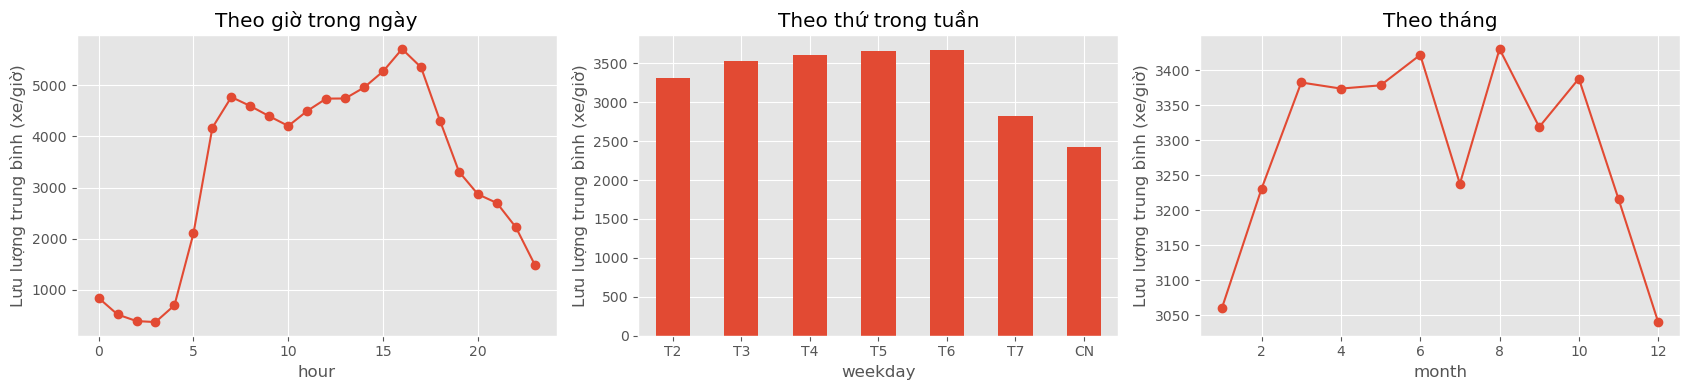

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
hourly.groupby("hour").traffic_volume.mean().plot(ax=axes[0], marker="o", title="Theo giờ trong ngày")
hourly.groupby("weekday").traffic_volume.mean().plot.bar(ax=axes[1], title="Theo thứ trong tuần")
axes[1].set_xticklabels(["T2", "T3", "T4", "T5", "T6", "T7", "CN"], rotation=0)
hourly.groupby("month").traffic_volume.mean().plot(ax=axes[2], marker="o", title="Theo tháng")
for ax in axes: ax.set_ylabel("Lưu lượng trung bình (xe/giờ)")
plt.tight_layout(); plt.show()
print("Giờ trung bình cao nhất:", hourly.groupby("hour").traffic_volume.mean().idxmax())

**Nhận xét:** Trung bình cao nhất lúc 16 giờ, khoảng 5.709 xe/giờ; thấp nhất lúc 3 giờ, khoảng 373 xe/giờ. Thứ Sáu khoảng 3.675 xe/giờ, cao hơn Chủ nhật khoảng 2.426. Tháng 8 có trung bình khoảng 3.430 và tháng 12 khoảng 3.040; độ phủ theo tháng không đồng đều nên cần thận trọng khi so sánh.

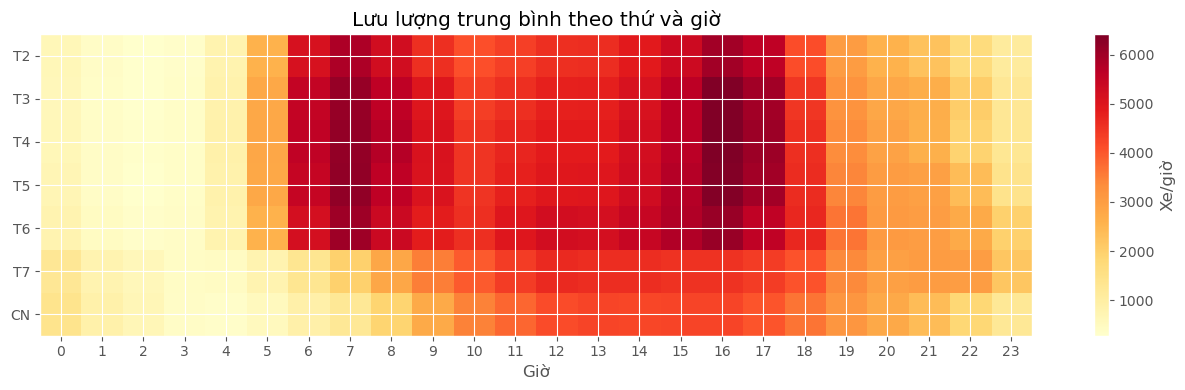

In [14]:
pivot = hourly.pivot_table(index="weekday", columns="hour", values="traffic_volume", aggfunc="mean")
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(pivot, aspect="auto", cmap="YlOrRd")
ax.set(xticks=range(24), yticks=range(7), yticklabels=["T2", "T3", "T4", "T5", "T6", "T7", "CN"], xlabel="Giờ", title="Lưu lượng trung bình theo thứ và giờ")
fig.colorbar(im, ax=ax, label="Xe/giờ")
plt.tight_layout(); plt.show()

**Nhận xét:** Biểu đồ cho phép đối chiếu trực tiếp giờ cao điểm giữa các ngày; cần xét riêng ngày làm việc và cuối tuần khi xây dựng đặc trưng.

## 4. Thời tiết và ngày lễ
Các phân tích sau dùng dòng gốc vì một timestamp có thể có nhiều mô tả thời tiết; do đó số dòng không tương đương số giờ độc lập. Ngày lễ được ghi tại một số timestamp, nên so sánh sau chỉ mang tính mô tả, không đại diện toàn bộ ngày lễ.

,mean,count
weather_main,,
Clouds,3618.449749,15164
Clear,3055.908819,13391
Mist,2932.956639,5950
Rain,3317.905501,5672
Snow,3016.844228,2876
Drizzle,3290.727073,1821
Haze,3502.101471,1360
Thunderstorm,3001.620890,1034
Fog,2703.720395,912


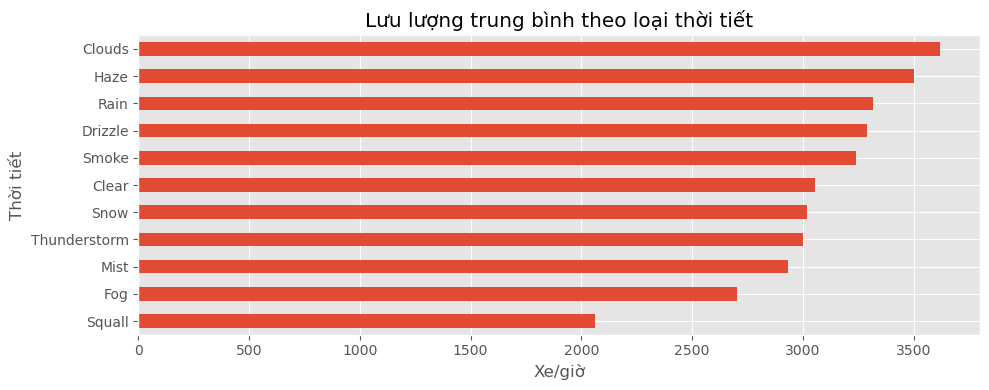

,mean,median,count
holiday_flag,,,
False,3262.852170,3385.0,48143
True,865.442623,812.0,61


In [17]:
weather = df.groupby("weather_main").traffic_volume.agg(["mean", "count"]).sort_values("count", ascending=False)
display(weather)
fig, ax = plt.subplots(figsize=(10, 4))
weather.sort_values("mean")["mean"].plot.barh(ax=ax)
ax.set(title="Lưu lượng trung bình theo loại thời tiết", xlabel="Xe/giờ", ylabel="Thời tiết")
plt.tight_layout(); plt.show()
df["holiday_flag"] = df.holiday.ne("None") & df.holiday.ne("")
display(df.groupby("holiday_flag").traffic_volume.agg(["mean", "median", "count"]))

**Nhận xét:** Clouds và Clear là hai nhóm thời tiết có nhiều bản ghi nhất. Chỉ 61 dòng có nhãn ngày lễ; nhãn này không đại diện toàn bộ các giờ trong ngày lễ nên không thể kết luận mức giảm lưu lượng của cả ngày từ bảng này.

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
temp,1.000000,0.009069,-0.019755,-0.101976,0.130299
rain_1h,0.009069,1.000000,-0.000090,0.004818,0.004714
snow_1h,-0.019755,-0.000090,1.000000,0.027931,0.000733
clouds_all,-0.101976,0.004818,0.027931,1.000000,0.067054
traffic_volume,0.130299,0.004714,0.000733,0.067054,1.000000


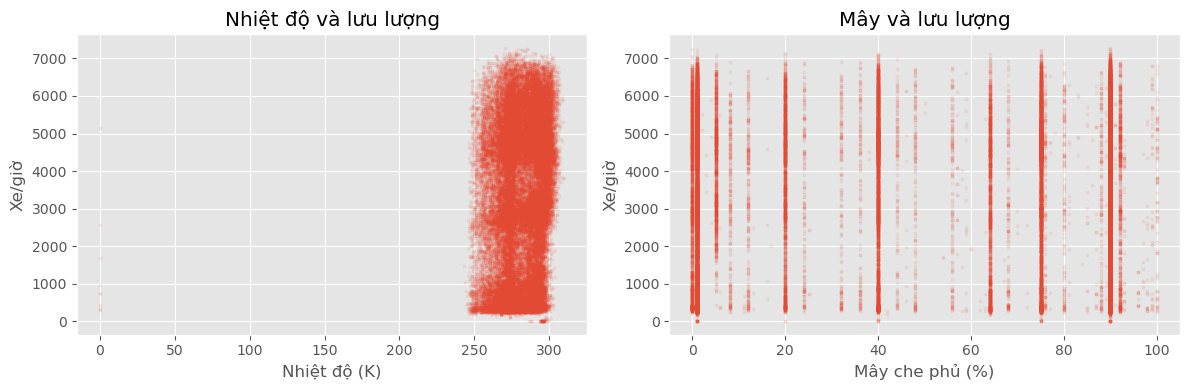

In [19]:
cols = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
display(df[cols].corr())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df.temp, df.traffic_volume, alpha=0.08, s=5)
axes[0].set(xlabel="Nhiệt độ (K)", ylabel="Xe/giờ", title="Nhiệt độ và lưu lượng")
axes[1].scatter(df.clouds_all, df.traffic_volume, alpha=0.08, s=5)
axes[1].set(xlabel="Mây che phủ (%)", ylabel="Xe/giờ", title="Mây và lưu lượng")
plt.tight_layout(); plt.show()

**Nhận xét:** Tương quan tuyến tính của nhiệt độ với lưu lượng khoảng 0,13; của mây khoảng 0,067, mưa khoảng 0,005 và tuyết khoảng 0,001. Các hệ số thấp không loại trừ quan hệ phi tuyến hay ảnh hưởng kết hợp với thời gian; cần kiểm tra các giá trị cực đoan.

## 5. Kết luận và bàn giao
- Lưu lượng có nhịp theo giờ và ngày trong tuần rõ rệt: 16 giờ cao nhất, cuối tuần thấp hơn các ngày trong tuần. Đề xuất thử đặc trưng giờ, thứ và cuối tuần.
- Quan hệ tuyến tính riêng lẻ giữa các biến thời tiết và lưu lượng yếu; cần đánh giá bằng mô hình và tránh kết luận quan hệ nhân quả.
- Timestamp lặp, khoảng trống thời gian và giá trị cực đoan cần được Phúc kiểm tra trước khi tiền xử lý. Tổng hợp theo giờ trong EDA chỉ phục vụ mô tả, không thay thế quyết định làm sạch.
- Nhãn ngày lễ chỉ xuất hiện ở một số bản ghi. Cần xem xét cách tạo đặc trưng ngày lễ cho cả ngày trước khi sử dụng.
- Chia tập theo thời gian như đề cương và tránh dùng thông tin tương lai khi tạo đặc trưng hoặc đánh giá.